## XAI Lab: Influence Functions and Counterfactuals

In [1]:
# pip install dice-ml "pandas<3"

In [2]:
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as T
import torchvision.models as models
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.neighbors import NearestNeighbors

import dice_ml

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [6]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Using device: {device}")

Using device: mps


Complete the coding exercises below.

#### Influence Functions:
- **Task (0.5 points):** Fine-tune the given model on the image dataset.
- **Task (1 point):** Using the helper functions, compute influence scores for a subset of training examples for a selected test image.
- **Task (1 point):** Plot the most influential training images for the chosen test image.

#### Counterfactuals (using DiCE library):
- **Task (0.5 points):** Train a logistic regression on the tabular dataset given.
- **Task (1.5 points):** Select a negatively predicted test instance and use DiCE to generate baseline counterfactual examples. Show the feature values of the original and the counterfactual.
- **Task (1.5 points):** Use DiCE's `features_to_vary` to add feasibility constraints to prevent changes to the subset of features that cannot be modified (analyse the features to determine that subset) and compare results.
- **Task (1.5 points):** Add the causal constraints given and generate counterfactuals again. Compare results.
- **Task (1.5 points):** Use DiCE's `kdtree` method to construct on-manifold counterfactuals. Compare all results.
- **Task (1 point):** Create a dot plot showing which numerical and categorical features changed for a selected test instance across the base, feasible, causal and manifold counterfactuals.

### Coding Tasks

In [3]:
transform = T.Compose([
    T.Resize(224),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

class_names = train_dataset.classes

100%|██████████| 170M/170M [06:24<00:00, 443kB/s]  


**Task (0.5 points):** Fine-tune the given model on the image dataset.

In [14]:
model = models.resnet18(pretrained=True)
model.fc = torch.nn.Linear(model.fc.in_features, 10)
model.maxpool = nn.AvgPool2d(kernel_size=3, stride=2, padding=1)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

In [15]:
num_epochs = 5
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    print(f"Epoch {epoch+1}/{num_epochs}, Loss: {epoch_loss:.4f}")

Epoch 1/5, Loss: 0.3450
Epoch 2/5, Loss: 0.1069
Epoch 3/5, Loss: 0.0463
Epoch 4/5, Loss: 0.0357
Epoch 5/5, Loss: 0.0303


In [16]:
# eval
model.eval()
correct = 0
total = 0
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the network on the 10000 test images: {100 * correct / total:.2f}%')

Accuracy of the network on the 10000 test images: 93.80%


In [17]:
def get_grad_vector(model, x, y):
    model.zero_grad()
    outputs = model(x)
    loss = criterion(outputs, y)
    grads = torch.autograd.grad(loss, model.parameters())
    grad_vector = torch.cat([g.contiguous().view(-1) for g in grads])
    return grad_vector.detach()

def hvp(model, loss, params, v):
    grads = torch.autograd.grad(loss, params, create_graph=True)
    grad_vector = torch.cat([g.contiguous().view(-1) for g in grads])
    hv = torch.autograd.grad(grad_vector, params, grad_outputs=v, retain_graph=True)
    hv = torch.cat([h.contiguous().view(-1) for h in hv])
    return hv

def lissa_inverse_hvp(model, test_x, test_y, train_loader, damping=0.01, scale=25.0, recursion_depth=30):
    v = get_grad_vector(model, test_x, test_y).to(device)
    cur_estimate = v.clone()

    for i in range(recursion_depth):
        imgs, labels = next(iter(train_loader))
        imgs = imgs.to(device)
        labels = labels.to(device)

        model.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)

        hv = hvp(model, loss, list(model.parameters()), cur_estimate)
        cur_estimate = v + (1 - damping) * cur_estimate - hv / scale

    return cur_estimate

**Task (1 point):** Using the helper functions, compute influence scores for a subset of training examples for a selected test image.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8952821..2.5877128].


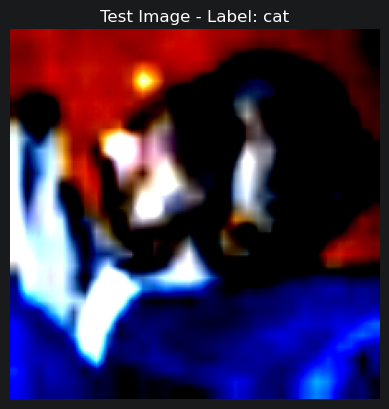

In [18]:
# Select a test image
test_idx = 0
test_image, test_label = test_dataset[test_idx]
test_image = test_image.unsqueeze(0).to(device)
test_label = torch.tensor([test_label]).to(device)

# Plot the test image
plt.imshow(test_image.cpu().squeeze().permute(1, 2, 0))
plt.title(f"Test Image - Label: {class_names[test_label.item()]}")
plt.axis("off")
plt.show()

In [19]:
# Compute the inverse Hessian-vector product
ihvp = lissa_inverse_hvp(model, test_image, test_label, train_loader)

**Task (1 point):** Plot the most influential training images for the chosen test image.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.843908..1.6465361].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.2914162].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.4404761..2.5702832].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.6555357..2.1309524].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0357141..2.64].


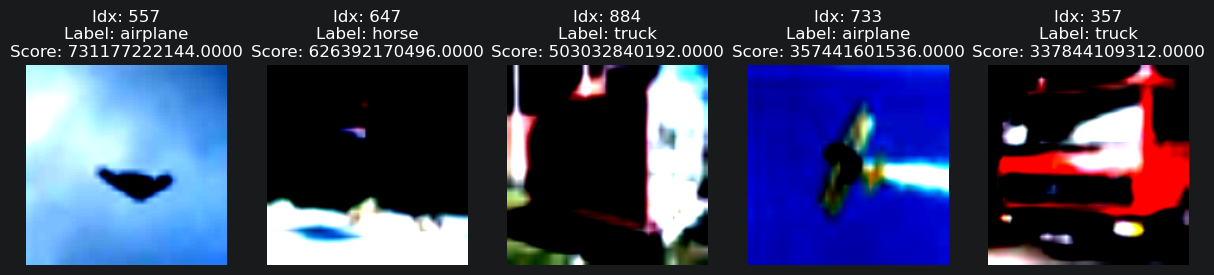

In [21]:
# Compute influence scores for a subset of training examples
influence_scores = []
for idx in range(1000):  # Compute for the first 1000 training examples
    train_image, train_label = train_dataset[idx]
    train_image = train_image.unsqueeze(0).to(device)
    train_label = torch.tensor([train_label]).to(device)
    model.zero_grad()
    outputs = model(train_image)
    loss = criterion(outputs, train_label)
    loss.backward()

    grad_vector = torch.cat([p.grad.contiguous().view(-1) for p in model.parameters()])
    influence_score = -torch.dot(grad_vector, ihvp).item()
    influence_scores.append((idx, influence_score))

# Sort by influence score
influence_scores.sort(key=lambda x: x[1], reverse=True)

# Plot the top 5 most influential training images
plt.figure(figsize=(15, 3))
for i in range(5):
    idx, score = influence_scores[i]
    train_image, train_label = train_dataset[idx]
    plt.subplot(1, 5, i + 1)
    plt.imshow(train_image.permute(1, 2, 0))
    plt.title(f"Idx: {idx}\nLabel: {class_names[train_label]}\nScore: {score:.4f}")
    plt.axis("off")
plt.show()

### Counterfactuals

In [22]:
adult = fetch_openml(name="adult", version=2, as_frame=True)

X = adult.data
y = adult.target

In [23]:
X.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States


In [24]:
numerical_features = [
    "age",
    "education-num",
    "capital-gain",
    "capital-loss",
    "hours-per-week"
]

categorical_features = [col for col in X.columns if col not in numerical_features]

print("Numerical:", numerical_features)
print("Categorical:", categorical_features)

numeric_transformer = Pipeline(steps=[("scaler", StandardScaler())])

categorical_transformer = Pipeline(steps=[("onehot", OneHotEncoder(handle_unknown="ignore"))])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

Numerical: ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical: ['workclass', 'fnlwgt', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


**Task (0.5 points):** Train a logistic regression on the tabular dataset given.

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}")

Test Accuracy: 0.8579


**Task (1.5 points):** Select a negatively predicted test instance and use DiCE to generate baseline counterfactual examples. Show the feature values of the original and the counterfactual.

In [37]:
# 1. Update your numerical features list to include fnlwgt
# I've added others that are often missed in the Adult dataset too
numerical_features = [
    'age', 'fnlwgt', 'education-num', 'capital-gain',
    'capital-loss', 'hours-per-week'
]

# 2. Re-combine data
train_df = X_train.copy()
train_df['income'] = y_train

# 3. Re-initialize the Data object with the corrected list
d = dice_ml.Data(
    dataframe=train_df,
    continuous_features=numerical_features,
    outcome_name="income"
)

# 4. Re-initialize the Model and Explainer
m = dice_ml.Model(model=model, backend="sklearn")
explainer = dice_ml.Dice(d, m, method="random")

# 5. Select test instance (same as before)
neg_indices = np.where((y_test == "<=50K") & (y_pred == "<=50K"))[0]
test_instance = X_test.iloc[neg_indices[0] : neg_indices[0] + 1]

# 6. Generate (should work now!)
counterfactuals = explainer.generate_counterfactuals(
    test_instance,
    total_CFs=3,
    desired_class="opposite"
)

counterfactuals.visualize_as_dataframe(show_only_changes=True)

100%|██████████| 1/1 [00:00<00:00,  6.33it/s]

Query instance (original outcome : <=50K)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,56,Private,33115,HS-grad,9,Divorced,Other-service,Unmarried,White,Female,0,0,40,United-States,<=50K



Diverse Counterfactual set (new outcome: >50K)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,-,-,-,-,-,-,-,-,-,-,76112,-,-,Nicaragua,>50K
1,-,-,-,-,-,-,-,Own-child,-,-,43056,-,-,-,>50K
2,-,-,-,-,-,-,-,-,-,-,91170,-,-,-,>50K


**Task (1.5 points):** Use DiCE's `features_to_vary` to add feasibility constraints to prevent changes to the subset of features that cannot be modified (analyse the features to determine that subset) and compare results.

In [27]:
# Your solution here..

**Task (1.5 points):** Add the causal constraints given and generate counterfactuals again. Compare results.

Causal Constraints:
age → education-num \
age → capital-gain \
education-num → hours-per-week \
hours-per-week → capital-gain

In [28]:
# Your solution here..

**Task (1.5 points):** Use DiCE's `kdtree` method to construct on-manifold counterfactuals. Compare all results.

In [29]:
# Your solution here..

**Task (1 point):** Create a dot plot showing which numerical and categorical features changed for a selected test instance across the base, feasible, causal and manifold counterfactuals.

In [30]:
# Your solution here..